# Chapter 8: Model Evaluation Metrics

> **Data** generated inline  (exercises use clinic_readmission.csv) · **Time** 120 min · **Needs first** C1b for the imbalance material

## What you will be able to do

1. Read a confusion matrix and compute precision, recall, F1 and specificity from it
2. Choose between precision, recall and F1 for a stated cost of error
3. Read an ROC curve and a precision-recall curve, and say when each is the right one
4. Compare regression models with MAE, RMSE and R-squared, and explain a disagreement between them
5. Diagnose a fitted model from its residual plot
6. Choose k from a silhouette plot and an elbow curve
7. Diagnose overfitting and underfitting from training curves

## The one idea to hold on to

A metric encodes what you are willing to be wrong about. Choose it before you fit anything, or you will choose it afterwards to suit the number you got.

## A Comprehensive Guide to Understanding and Interpreting ML Metrics

---

**Learning Objectives:**
- Understand why accuracy alone is insufficient for model evaluation
- Master classification metrics: Confusion Matrix, Precision, Recall, F1, ROC-AUC
- Learn regression metrics: MAE, MSE, RMSE, R-squared
- Explore clustering metrics: Silhouette Score, Davies-Bouldin Index
- Interpret evaluation curves and visualizations
- Choose the right metric for different problem types

**Duration:** ~2 hours

**Prerequisites:** Module 03 (Statistics), Module 04 (Preprocessing basics)

## 1. Introduction: Why Evaluation Metrics Matter

### The Accuracy Trap

Imagine a model predicting credit card fraud where only 1% of transactions are fraudulent:

| Model | Prediction | Accuracy |
|-------|------------|----------|
| Model A | Predicts "Not Fraud" for everything | 99% |
| Model B | Actually detects 80% of fraud cases | 98.5% |

**Model A has higher accuracy but is completely useless!** It catches zero fraud cases.

This is why we need multiple evaluation metrics that capture different aspects of model performance.

### Metric Categories

| Problem Type | Key Metrics |
|--------------|-------------|
| **Classification** | Accuracy, Precision, Recall, F1-Score, ROC-AUC |
| **Regression** | MAE, MSE, RMSE, R-squared |
| **Clustering** | Silhouette Score, Davies-Bouldin, Calinski-Harabasz |

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Classification metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, precision_recall_curve, auc
)

# Regression metrics
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_absolute_percentage_error
)

# Clustering metrics
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score
)

# Models for examples
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification, make_regression, make_blobs

# Display settings
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


---

## 2. Classification Metrics

### 2.1 The Confusion Matrix

The confusion matrix is the foundation of all classification metrics.

```
                    PREDICTED
                 Negative  Positive
            +-----------+-----------+
  ACTUAL    |    TN     |    FP     |   Negative
            +-----------+-----------+
            |    FN     |    TP     |   Positive
            +-----------+-----------+
```

**Understanding Each Cell:**

| Term | Full Name | Meaning | Example (Fraud Detection) |
|------|-----------|---------|---------------------------|
| **TP** | True Positive | Correctly predicted positive | Fraud correctly flagged |
| **TN** | True Negative | Correctly predicted negative | Legitimate correctly passed |
| **FP** | False Positive | Incorrectly predicted positive | Legitimate flagged as fraud (Type I Error) |
| **FN** | False Negative | Incorrectly predicted negative | Fraud missed (Type II Error) |

In [2]:
# Create sample classification data
np.random.seed(42)
X, y = make_classification(
    n_samples=1000, 
    n_features=10, 
    n_informative=5,
    n_redundant=2,
    weights=[0.7, 0.3],  # Slightly imbalanced
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train a simple model
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(f"Test set size: {len(y_test)}")
print(f"Class distribution: {np.bincount(y_test)}")

Test set size: 300
Class distribution: [193 107]


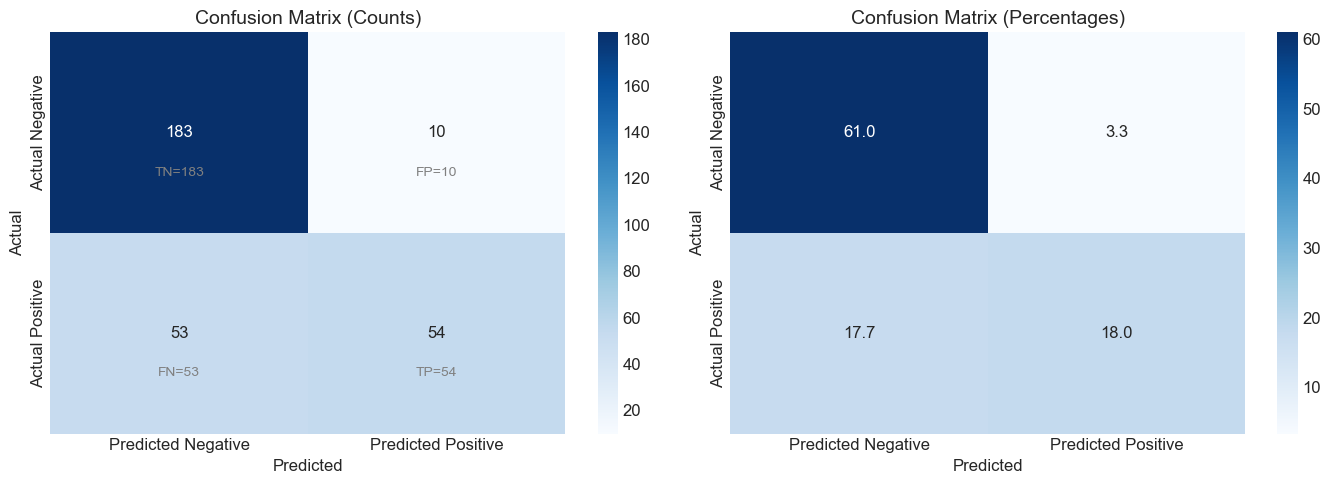


Confusion Matrix Values:
True Negatives (TN): 183
False Positives (FP): 10
False Negatives (FN): 53
True Positives (TP): 54


In [3]:
# Visualize Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
axes[0].set_title('Confusion Matrix (Counts)', fontsize=14)
axes[0].set_ylabel('Actual', fontsize=12)
axes[0].set_xlabel('Predicted', fontsize=12)

# Add labels
tn, fp, fn, tp = cm.ravel()
axes[0].text(0.5, 0.7, f'TN={tn}', ha='center', va='center', fontsize=10, color='gray')
axes[0].text(1.5, 0.7, f'FP={fp}', ha='center', va='center', fontsize=10, color='gray')
axes[0].text(0.5, 1.7, f'FN={fn}', ha='center', va='center', fontsize=10, color='gray')
axes[0].text(1.5, 1.7, f'TP={tp}', ha='center', va='center', fontsize=10, color='gray')

# Normalized (percentages)
cm_normalized = cm.astype('float') / cm.sum() * 100
sns.heatmap(cm_normalized, annot=True, fmt='.1f', cmap='Blues', ax=axes[1],
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
axes[1].set_title('Confusion Matrix (Percentages)', fontsize=14)
axes[1].set_ylabel('Actual', fontsize=12)
axes[1].set_xlabel('Predicted', fontsize=12)

plt.tight_layout()
plt.show()

print(f"\nConfusion Matrix Values:")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")

### 2.2 Core Classification Metrics

#### Accuracy
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

**When to use:** Balanced datasets  
**When NOT to use:** Imbalanced datasets (fraud, disease detection)

---

#### Precision (Positive Predictive Value)
$$\text{Precision} = \frac{TP}{TP + FP}$$

**Question it answers:** "Of all predicted positives, how many are actually positive?"

**High precision matters when:** False positives are costly
- Spam detection (don't want to send important emails to spam)
- Legal recommendations (false accusations are costly)

---

#### Recall (Sensitivity, True Positive Rate)
$$\text{Recall} = \frac{TP}{TP + FN}$$

**Question it answers:** "Of all actual positives, how many did we correctly identify?"

**High recall matters when:** False negatives are costly
- Cancer detection (don't want to miss cancer cases)
- Fraud detection (don't want to miss fraud)

---

#### F1-Score
$$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

**Harmonic mean** of precision and recall. Penalizes extreme values.

**When to use:** When you need balance between precision and recall

---

#### Specificity (True Negative Rate)
$$\text{Specificity} = \frac{TN}{TN + FP}$$

**Question it answers:** "Of all actual negatives, how many did we correctly identify?"

In [4]:
# Calculate all metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
specificity = tn / (tn + fp)

# Create metrics summary
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'Specificity', 'F1-Score'],
    'Formula': [
        '(TP+TN) / (TP+TN+FP+FN)',
        'TP / (TP+FP)',
        'TP / (TP+FN)',
        'TN / (TN+FP)',
        '2 * (Prec*Rec) / (Prec+Rec)'
    ],
    'Value': [accuracy, precision, recall, specificity, f1],
    'Interpretation': [
        f'{accuracy:.1%} of all predictions were correct',
        f'{precision:.1%} of predicted positives were correct',
        f'{recall:.1%} of actual positives were found',
        f'{specificity:.1%} of actual negatives were identified',
        f'Harmonic mean balancing precision and recall'
    ]
})

print("=" * 80)
print("CLASSIFICATION METRICS SUMMARY")
print("=" * 80)
for _, row in metrics_df.iterrows():
    print(f"\n{row['Metric']}")
    print(f"  Formula: {row['Formula']}")
    print(f"  Value: {row['Value']:.4f}")
    print(f"  Meaning: {row['Interpretation']}")

CLASSIFICATION METRICS SUMMARY

Accuracy
  Formula: (TP+TN) / (TP+TN+FP+FN)
  Value: 0.7900
  Meaning: 79.0% of all predictions were correct

Precision
  Formula: TP / (TP+FP)
  Value: 0.8438
  Meaning: 84.4% of predicted positives were correct

Recall (Sensitivity)
  Formula: TP / (TP+FN)
  Value: 0.5047
  Meaning: 50.5% of actual positives were found

Specificity
  Formula: TN / (TN+FP)
  Value: 0.9482
  Meaning: 94.8% of actual negatives were identified

F1-Score
  Formula: 2 * (Prec*Rec) / (Prec+Rec)
  Value: 0.6316
  Meaning: Harmonic mean balancing precision and recall


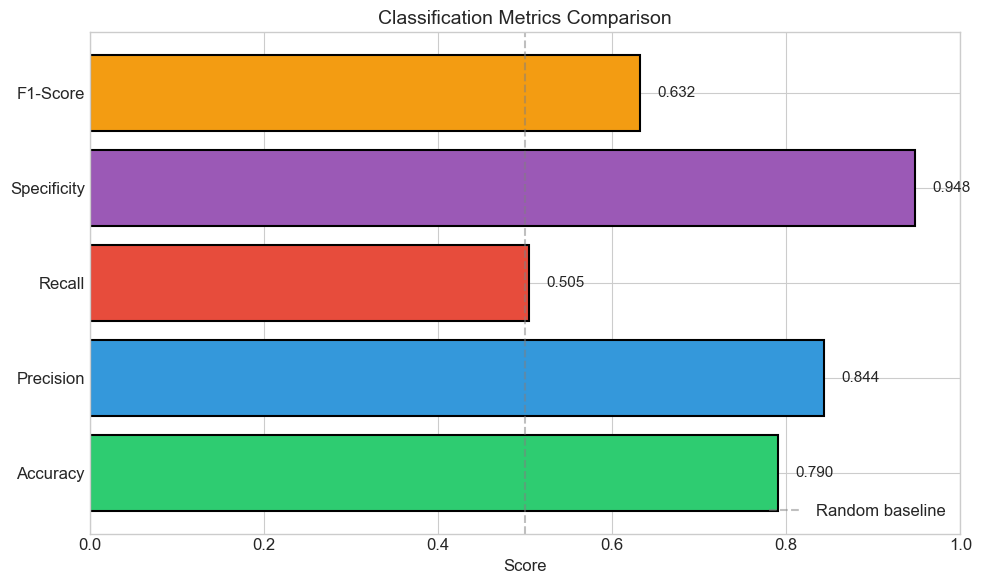

In [5]:
# Visual comparison of metrics
fig, ax = plt.subplots(figsize=(10, 6))

metrics = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1-Score']
values = [accuracy, precision, recall, specificity, f1]
colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6', '#f39c12']

bars = ax.barh(metrics, values, color=colors, edgecolor='black', linewidth=1.5)
ax.set_xlim(0, 1)
ax.set_xlabel('Score', fontsize=12)
ax.set_title('Classification Metrics Comparison', fontsize=14)

# Add value labels
for bar, value in zip(bars, values):
    ax.text(value + 0.02, bar.get_y() + bar.get_height()/2, 
            f'{value:.3f}', va='center', fontsize=11)

# Add vertical line at 0.5 (random baseline)
ax.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5, label='Random baseline')
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [6]:
# Full classification report
print("\n" + "=" * 60)
print("SKLEARN CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))


SKLEARN CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.78      0.95      0.85       193
    Positive       0.84      0.50      0.63       107

    accuracy                           0.79       300
   macro avg       0.81      0.73      0.74       300
weighted avg       0.80      0.79      0.77       300



### 2.3 Multi-Class F1 Variants

For multi-class problems, we have different ways to aggregate F1-Score:

| Variant | Calculation | Best For |
|---------|-------------|----------|
| **Macro F1** | Average of per-class F1 scores | Balanced importance across classes |
| **Weighted F1** | Weighted average by class support | Class imbalance exists |
| **Micro F1** | Global TP, FP, FN aggregation | Overall performance |

In [7]:
# Create multi-class example
X_multi, y_multi = make_classification(
    n_samples=1000, n_features=10, n_informative=5,
    n_classes=3, n_clusters_per_class=1, random_state=42
)

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.3, random_state=42
)

model_multi = LogisticRegression(random_state=42, max_iter=1000)
model_multi.fit(X_train_m, y_train_m)
y_pred_m = model_multi.predict(X_test_m)

# Calculate different F1 variants
f1_macro = f1_score(y_test_m, y_pred_m, average='macro')
f1_weighted = f1_score(y_test_m, y_pred_m, average='weighted')
f1_micro = f1_score(y_test_m, y_pred_m, average='micro')

print("Multi-Class F1 Score Variants:")
print(f"  Macro F1:    {f1_macro:.4f} (unweighted average)")
print(f"  Weighted F1: {f1_weighted:.4f} (weighted by support)")
print(f"  Micro F1:    {f1_micro:.4f} (global aggregation)")
print(f"\nClass distribution: {np.bincount(y_test_m)}")

Multi-Class F1 Score Variants:
  Macro F1:    0.9371 (unweighted average)
  Weighted F1: 0.9367 (weighted by support)
  Micro F1:    0.9367 (global aggregation)

Class distribution: [ 97 101 102]


### 2.4 ROC Curve and AUC

The **ROC (Receiver Operating Characteristic)** curve plots:
- **X-axis:** False Positive Rate (FPR) = FP / (FP + TN)
- **Y-axis:** True Positive Rate (TPR) = Recall = TP / (TP + FN)

**AUC (Area Under the Curve)** Interpretation:

| AUC Value | Interpretation |
|-----------|----------------|
| 1.0 | Perfect classifier |
| 0.9 - 1.0 | Excellent |
| 0.8 - 0.9 | Good |
| 0.7 - 0.8 | Fair |
| 0.5 - 0.7 | Poor |
| 0.5 | Random classifier (no discrimination) |

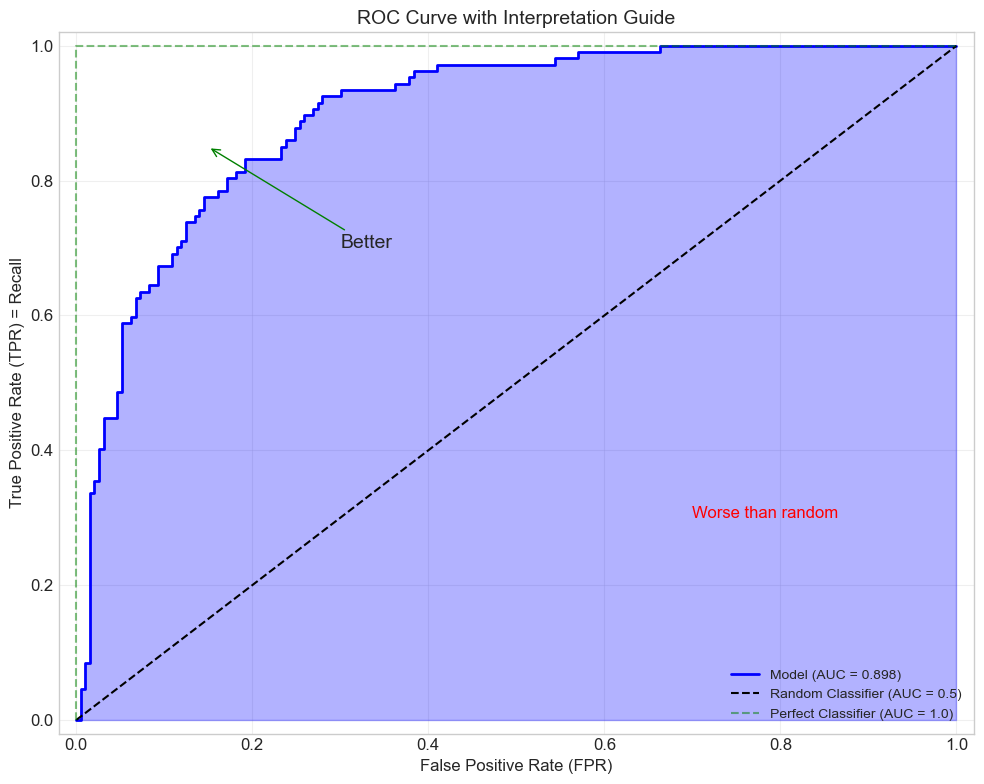


ROC-AUC Score: 0.8984

Interpretation: The model has a 89.8% probability of ranking a random positive
instance higher than a random negative instance.


In [8]:
# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

# Create annotated ROC curve
fig, ax = plt.subplots(figsize=(10, 8))

# Plot ROC curve
ax.plot(fpr, tpr, 'b-', linewidth=2, label=f'Model (AUC = {roc_auc:.3f})')

# Random classifier line
ax.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier (AUC = 0.5)')

# Perfect classifier
ax.plot([0, 0, 1], [0, 1, 1], 'g--', linewidth=1.5, alpha=0.5, label='Perfect Classifier (AUC = 1.0)')

# Fill area under curve
ax.fill_between(fpr, tpr, alpha=0.3, color='blue')

# Annotations
ax.annotate('Better', xy=(0.15, 0.85), fontsize=14, 
            arrowprops=dict(arrowstyle='->', color='green'),
            xytext=(0.3, 0.7))

ax.annotate('Worse than random', xy=(0.7, 0.3), fontsize=12, color='red')

# Styling
ax.set_xlabel('False Positive Rate (FPR)', fontsize=12)
ax.set_ylabel('True Positive Rate (TPR) = Recall', fontsize=12)
ax.set_title('ROC Curve with Interpretation Guide', fontsize=14)
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])

# Add grid
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nROC-AUC Score: {roc_auc:.4f}")
print(f"\nInterpretation: The model has a {roc_auc:.1%} probability of ranking a random positive")
print(f"instance higher than a random negative instance.")

### 2.5 Precision-Recall Curve

The **Precision-Recall Curve** is particularly useful for **imbalanced datasets** where ROC-AUC can be misleading.

- **X-axis:** Recall
- **Y-axis:** Precision

**When to prefer PR curve over ROC:**
- Highly imbalanced data (rare positive class)
- When false positives and false negatives have different costs
- When the positive class is what you care about most

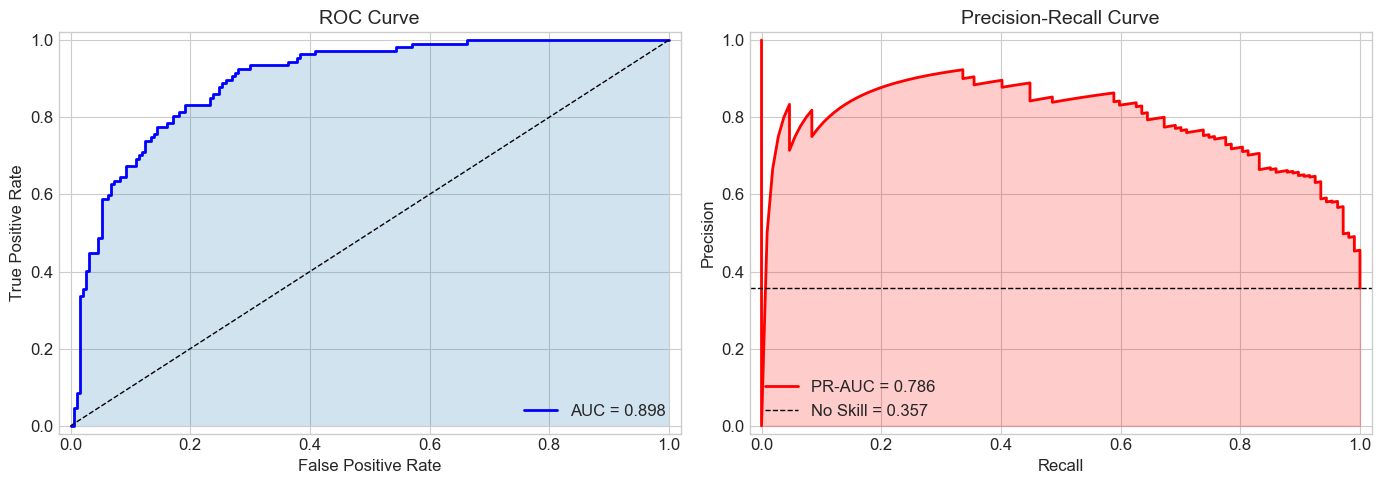

In [9]:
# Calculate Precision-Recall curve
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_test, y_proba)
pr_auc = auc(recall_curve, precision_curve)

# Create side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
axes[0].plot(fpr, tpr, 'b-', linewidth=2, label=f'AUC = {roc_auc:.3f}')
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].fill_between(fpr, tpr, alpha=0.2)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve', fontsize=14)
axes[0].legend(loc='lower right')
axes[0].set_xlim([-0.02, 1.02])
axes[0].set_ylim([-0.02, 1.02])

# PR Curve
axes[1].plot(recall_curve, precision_curve, 'r-', linewidth=2, label=f'PR-AUC = {pr_auc:.3f}')
# Baseline for PR curve (proportion of positives)
no_skill = sum(y_test) / len(y_test)
axes[1].axhline(y=no_skill, color='k', linestyle='--', linewidth=1, label=f'No Skill = {no_skill:.3f}')
axes[1].fill_between(recall_curve, precision_curve, alpha=0.2, color='red')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve', fontsize=14)
axes[1].legend(loc='lower left')
axes[1].set_xlim([-0.02, 1.02])
axes[1].set_ylim([-0.02, 1.02])

plt.tight_layout()
plt.show()

### 2.6 Threshold Selection: Precision-Recall Trade-off

By default, classifiers use 0.5 as the threshold for binary predictions. Adjusting this threshold allows you to trade off between precision and recall.

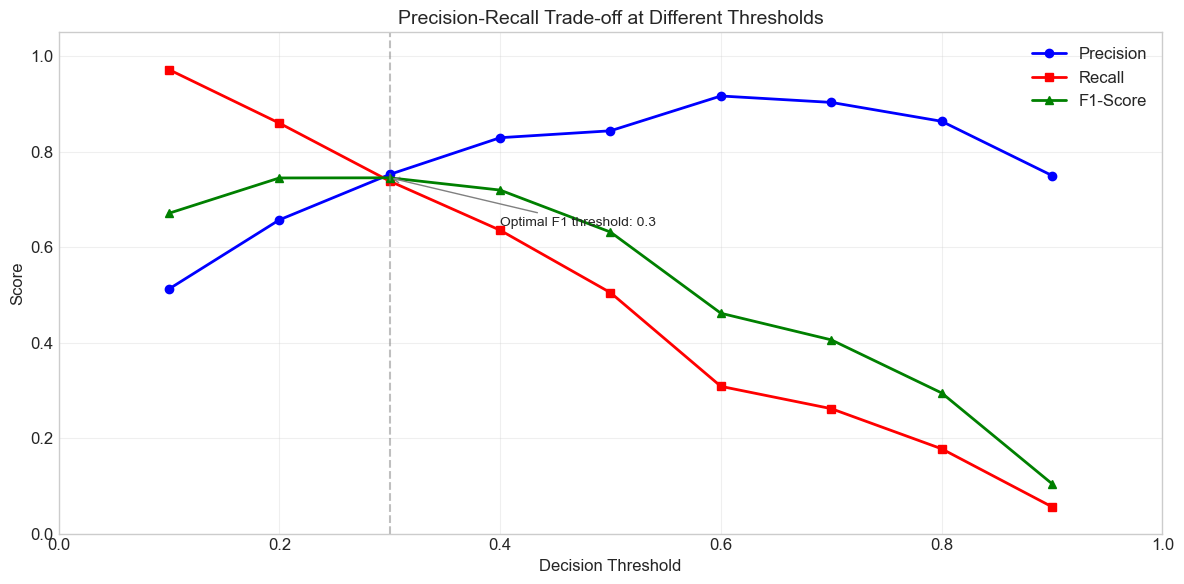


Threshold Analysis:
 Threshold  Precision   Recall       F1
       0.1   0.512315 0.971963 0.670968
       0.2   0.657143 0.859813 0.744939
       0.3   0.752381 0.738318 0.745283
       0.4   0.829268 0.635514 0.719577
       0.5   0.843750 0.504673 0.631579
       0.6   0.916667 0.308411 0.461538
       0.7   0.903226 0.261682 0.405797
       0.8   0.863636 0.177570 0.294574
       0.9   0.750000 0.056075 0.104348


In [10]:
# Analyze different thresholds
thresholds_to_try = np.arange(0.1, 1.0, 0.1)
results = []

for threshold in thresholds_to_try:
    y_pred_thresh = (y_proba >= threshold).astype(int)
    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_test, y_pred_thresh, zero_division=0),
        'Recall': recall_score(y_test, y_pred_thresh),
        'F1': f1_score(y_test, y_pred_thresh)
    })

results_df = pd.DataFrame(results)

# Visualize threshold effects
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(results_df['Threshold'], results_df['Precision'], 'b-o', label='Precision', linewidth=2)
ax.plot(results_df['Threshold'], results_df['Recall'], 'r-s', label='Recall', linewidth=2)
ax.plot(results_df['Threshold'], results_df['F1'], 'g-^', label='F1-Score', linewidth=2)

# Mark optimal F1
best_idx = results_df['F1'].idxmax()
best_threshold = results_df.loc[best_idx, 'Threshold']
best_f1 = results_df.loc[best_idx, 'F1']
ax.axvline(x=best_threshold, color='gray', linestyle='--', alpha=0.5)
ax.annotate(f'Optimal F1 threshold: {best_threshold:.1f}', 
            xy=(best_threshold, best_f1), 
            xytext=(best_threshold + 0.1, best_f1 - 0.1),
            fontsize=10,
            arrowprops=dict(arrowstyle='->', color='gray'))

ax.set_xlabel('Decision Threshold', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Precision-Recall Trade-off at Different Thresholds', fontsize=14)
ax.legend(loc='best')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nThreshold Analysis:")
print(results_df.to_string(index=False))

---

## 3. Regression Metrics

### 3.1 Error Metrics Overview

| Metric | Formula | Interpretation |
|--------|---------|----------------|
| **MAE** | $\frac{1}{n}\sum|y_i - \hat{y}_i|$ | Average absolute error (same units as target) |
| **MSE** | $\frac{1}{n}\sum(y_i - \hat{y}_i)^2$ | Squares errors (penalizes large errors more) |
| **RMSE** | $\sqrt{\frac{1}{n}\sum(y_i - \hat{y}_i)^2}$ | Root of MSE (back to original units) |
| **MAPE** | $\frac{100}{n}\sum|\frac{y_i - \hat{y}_i}{y_i}|$ | Percentage error |
| **R-squared** | $1 - \frac{SS_{res}}{SS_{tot}}$ | Proportion of variance explained (0-1) |

In [11]:
# Create regression example
np.random.seed(42)
X_reg, y_reg = make_regression(n_samples=500, n_features=5, noise=20, random_state=42)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42
)

# Train regression model
reg_model = LinearRegression()
reg_model.fit(X_train_r, y_train_r)
y_pred_r = reg_model.predict(X_test_r)

# Calculate all regression metrics
mae = mean_absolute_error(y_test_r, y_pred_r)
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_r, y_pred_r)

# MAPE (handle zero values)
mask = y_test_r != 0
mape = np.mean(np.abs((y_test_r[mask] - y_pred_r[mask]) / y_test_r[mask])) * 100

print("=" * 60)
print("REGRESSION METRICS SUMMARY")
print("=" * 60)
print(f"\nMAE (Mean Absolute Error):     {mae:.4f}")
print(f"   Interpretation: On average, predictions are off by {mae:.2f} units")
print(f"\nMSE (Mean Squared Error):      {mse:.4f}")
print(f"   Interpretation: Squared error (penalizes large errors)")
print(f"\nRMSE (Root Mean Squared Error): {rmse:.4f}")
print(f"   Interpretation: Typical prediction error is {rmse:.2f} units")
print(f"\nMAPE (Mean Absolute % Error):  {mape:.2f}%")
print(f"   Interpretation: Predictions are off by {mape:.1f}% on average")
print(f"\nR-squared:                     {r2:.4f}")
print(f"   Interpretation: Model explains {r2:.1%} of variance in the target")

REGRESSION METRICS SUMMARY

MAE (Mean Absolute Error):     16.5005
   Interpretation: On average, predictions are off by 16.50 units

MSE (Mean Squared Error):      413.8231
   Interpretation: Squared error (penalizes large errors)

RMSE (Root Mean Squared Error): 20.3426
   Interpretation: Typical prediction error is 20.34 units

MAPE (Mean Absolute % Error):  42.25%
   Interpretation: Predictions are off by 42.2% on average

R-squared:                     0.9677
   Interpretation: Model explains 96.8% of variance in the target


### 3.2 R-squared (Coefficient of Determination)

$$R^2 = 1 - \frac{SS_{residual}}{SS_{total}} = 1 - \frac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$$

**Interpretation:**

| R-squared | Interpretation |
|-----------|----------------|
| 1.0 | Perfect fit (all variance explained) |
| 0.9+ | Excellent fit |
| 0.7-0.9 | Good fit |
| 0.5-0.7 | Moderate fit |
| 0.3-0.5 | Weak fit |
| < 0.3 | Poor fit |
| < 0 | Model is worse than predicting mean |

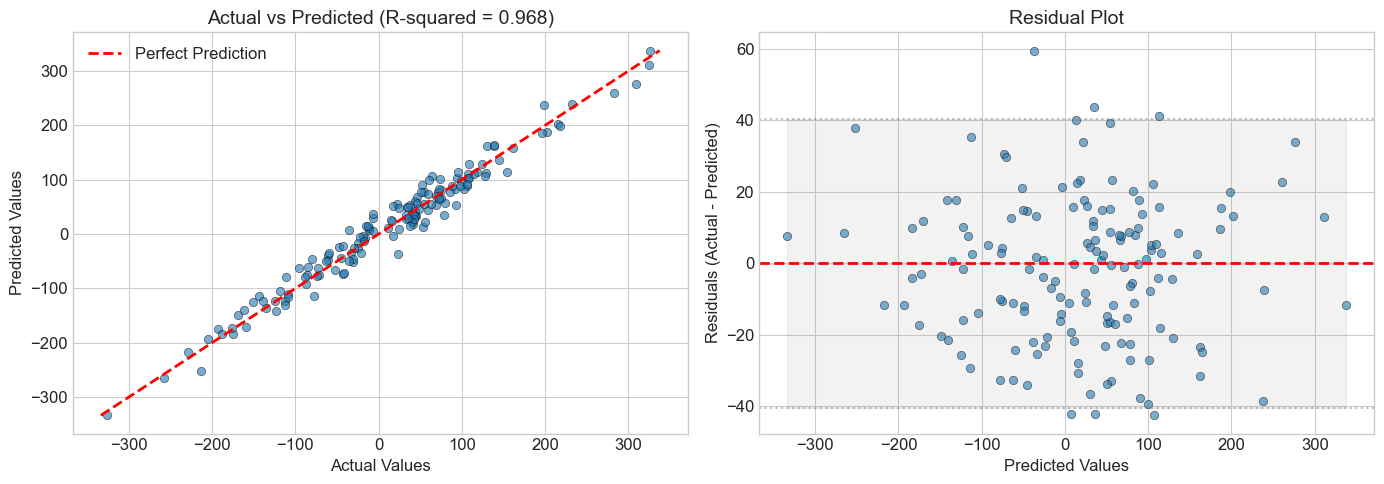

In [12]:
# Visualize actual vs predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot: Actual vs Predicted
axes[0].scatter(y_test_r, y_pred_r, alpha=0.6, edgecolors='black', linewidth=0.5)
# Perfect prediction line
min_val = min(y_test_r.min(), y_pred_r.min())
max_val = max(y_test_r.max(), y_pred_r.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Values', fontsize=12)
axes[0].set_ylabel('Predicted Values', fontsize=12)
axes[0].set_title(f'Actual vs Predicted (R-squared = {r2:.3f})', fontsize=14)
axes[0].legend()

# Residual plot
residuals = y_test_r - y_pred_r
axes[1].scatter(y_pred_r, residuals, alpha=0.6, edgecolors='black', linewidth=0.5)
axes[1].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[1].set_xlabel('Predicted Values', fontsize=12)
axes[1].set_ylabel('Residuals (Actual - Predicted)', fontsize=12)
axes[1].set_title('Residual Plot', fontsize=14)

# Add confidence bands
std_residual = np.std(residuals)
axes[1].axhline(y=2*std_residual, color='gray', linestyle=':', alpha=0.5)
axes[1].axhline(y=-2*std_residual, color='gray', linestyle=':', alpha=0.5)
axes[1].fill_between([y_pred_r.min(), y_pred_r.max()], 
                      -2*std_residual, 2*std_residual, alpha=0.1, color='gray')

plt.tight_layout()
plt.show()

### 3.3 Residual Analysis: What to Look For

Residual plots help diagnose model problems:

| Pattern | Problem | Solution |
|---------|---------|----------|
| Random scatter around 0 | Good model fit | None needed |
| Funnel shape | Heteroscedasticity | Transform target, use weighted regression |
| Curved pattern | Non-linearity missed | Add polynomial features |
| Clustered residuals | Model underspecified | Add more features |

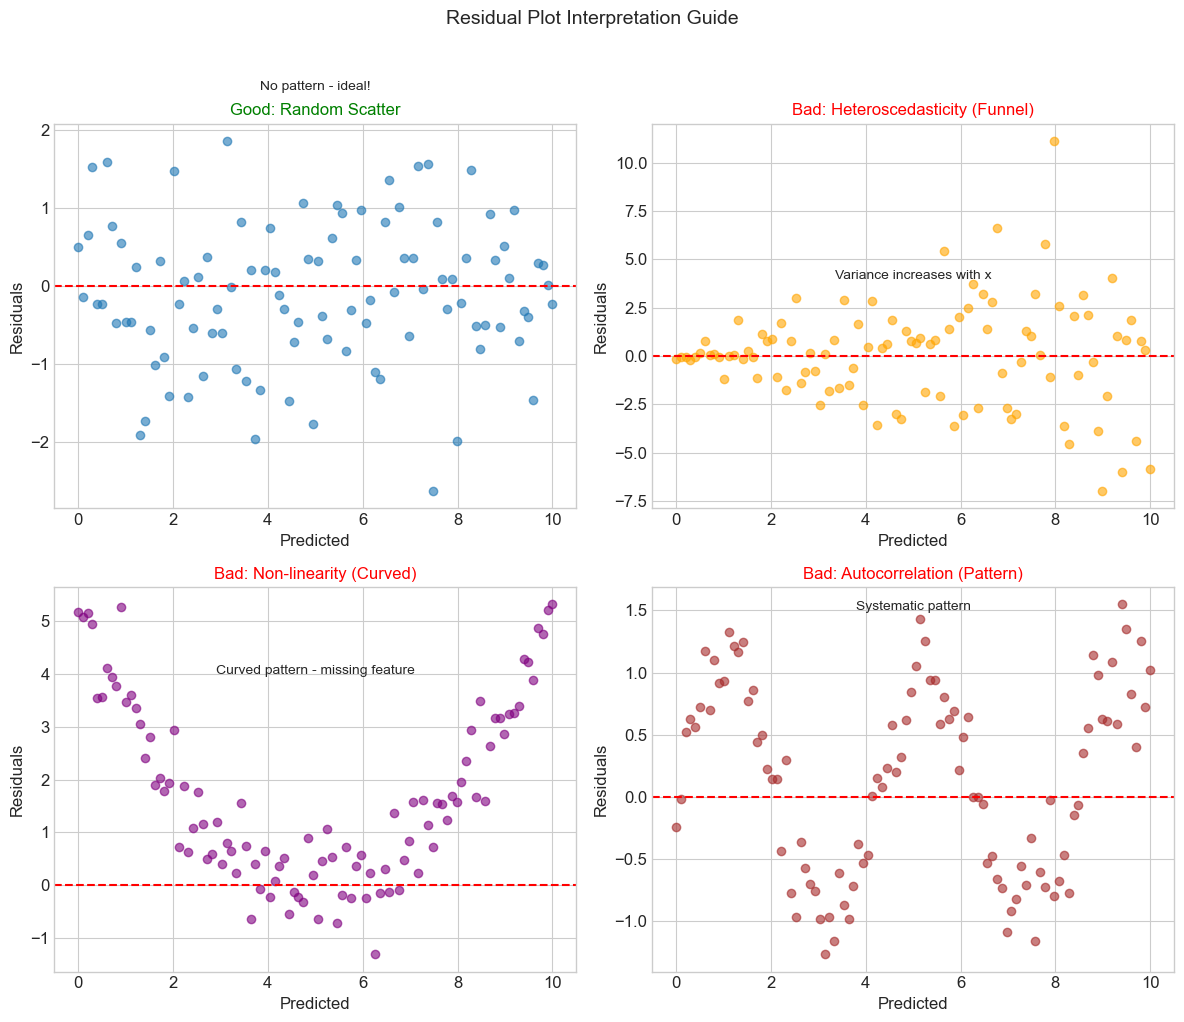

In [13]:
# Create examples of good vs problematic residual patterns
np.random.seed(42)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Good residuals (random scatter)
x = np.linspace(0, 10, 100)
good_residuals = np.random.normal(0, 1, 100)
axes[0, 0].scatter(x, good_residuals, alpha=0.6)
axes[0, 0].axhline(y=0, color='r', linestyle='--')
axes[0, 0].set_title('Good: Random Scatter', fontsize=12, color='green')
axes[0, 0].set_xlabel('Predicted')
axes[0, 0].set_ylabel('Residuals')
axes[0, 0].text(5, 2.5, 'No pattern - ideal!', ha='center', fontsize=10)

# 2. Heteroscedasticity (funnel shape)
funnel_residuals = np.random.normal(0, x/2 + 0.1, 100)
axes[0, 1].scatter(x, funnel_residuals, alpha=0.6, color='orange')
axes[0, 1].axhline(y=0, color='r', linestyle='--')
axes[0, 1].set_title('Bad: Heteroscedasticity (Funnel)', fontsize=12, color='red')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('Residuals')
axes[0, 1].text(5, 4, 'Variance increases with x', ha='center', fontsize=10)

# 3. Non-linearity (curved pattern)
curved_residuals = (x - 5)**2 / 5 + np.random.normal(0, 0.5, 100)
axes[1, 0].scatter(x, curved_residuals, alpha=0.6, color='purple')
axes[1, 0].axhline(y=0, color='r', linestyle='--')
axes[1, 0].set_title('Bad: Non-linearity (Curved)', fontsize=12, color='red')
axes[1, 0].set_xlabel('Predicted')
axes[1, 0].set_ylabel('Residuals')
axes[1, 0].text(5, 4, 'Curved pattern - missing feature', ha='center', fontsize=10)

# 4. Autocorrelation (pattern in sequence)
auto_residuals = np.sin(x * 1.5) + np.random.normal(0, 0.3, 100)
axes[1, 1].scatter(x, auto_residuals, alpha=0.6, color='brown')
axes[1, 1].axhline(y=0, color='r', linestyle='--')
axes[1, 1].set_title('Bad: Autocorrelation (Pattern)', fontsize=12, color='red')
axes[1, 1].set_xlabel('Predicted')
axes[1, 1].set_ylabel('Residuals')
axes[1, 1].text(5, 1.5, 'Systematic pattern', ha='center', fontsize=10)

plt.suptitle('Residual Plot Interpretation Guide', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---

## 4. Clustering Metrics

Clustering is **unsupervised** - we don't have ground truth labels. We use **internal metrics** to evaluate cluster quality.

### 4.1 Silhouette Score

Measures how similar a point is to its own cluster vs other clusters.

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

Where:
- $a(i)$ = average distance to points in same cluster
- $b(i)$ = average distance to points in nearest other cluster

| Silhouette Score | Interpretation |
|------------------|----------------|
| 0.7 - 1.0 | Strong cluster structure |
| 0.5 - 0.7 | Reasonable structure |
| 0.25 - 0.5 | Weak structure |
| < 0.25 | No substantial structure |

In [14]:
# Create clustering example
np.random.seed(42)
X_cluster, y_cluster_true = make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=42)

# Apply K-Means
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_cluster)

# Calculate metrics
silhouette_avg = silhouette_score(X_cluster, cluster_labels)
db_score = davies_bouldin_score(X_cluster, cluster_labels)
ch_score = calinski_harabasz_score(X_cluster, cluster_labels)

print("=" * 60)
print("CLUSTERING METRICS SUMMARY")
print("=" * 60)
print(f"\nSilhouette Score: {silhouette_avg:.4f}")
print(f"   Range: [-1, 1], higher is better")
print(f"   Interpretation: {'Strong' if silhouette_avg > 0.5 else 'Moderate' if silhouette_avg > 0.25 else 'Weak'} cluster structure")
print(f"\nDavies-Bouldin Index: {db_score:.4f}")
print(f"   Range: [0, inf), lower is better")
print(f"   Interpretation: Average similarity between clusters")
print(f"\nCalinski-Harabasz Index: {ch_score:.4f}")
print(f"   Range: [0, inf), higher is better")
print(f"   Interpretation: Ratio of between-cluster to within-cluster dispersion")

CLUSTERING METRICS SUMMARY

Silhouette Score: 0.7911
   Range: [-1, 1], higher is better
   Interpretation: Strong cluster structure

Davies-Bouldin Index: 0.2939
   Range: [0, inf), lower is better
   Interpretation: Average similarity between clusters

Calinski-Harabasz Index: 5742.0358
   Range: [0, inf), higher is better
   Interpretation: Ratio of between-cluster to within-cluster dispersion


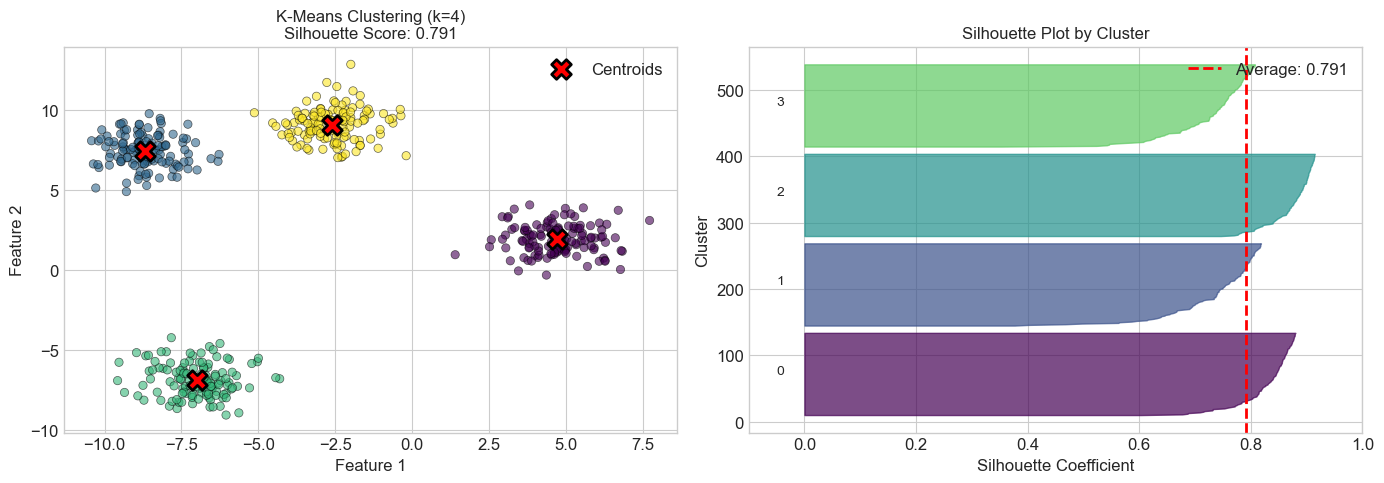


Silhouette Plot Interpretation:
- Each colored band represents one cluster
- Width of band = number of samples in cluster
- Bars extending past the red line = well-clustered points
- Bars below 0 = potentially misclassified points


In [15]:
# Silhouette plot
from sklearn.metrics import silhouette_samples

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Cluster visualization
scatter = axes[0].scatter(X_cluster[:, 0], X_cluster[:, 1], c=cluster_labels, 
                           cmap='viridis', alpha=0.6, edgecolors='black', linewidth=0.5)
axes[0].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
                c='red', marker='X', s=200, edgecolors='black', linewidth=2, label='Centroids')
axes[0].set_title(f'K-Means Clustering (k=4)\nSilhouette Score: {silhouette_avg:.3f}', fontsize=12)
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
axes[0].legend()

# Right: Silhouette plot
sample_silhouette_values = silhouette_samples(X_cluster, cluster_labels)
y_lower = 10

for i in range(4):
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()
    
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i
    
    color = plt.cm.viridis(float(i) / 4)
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)
    axes[1].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=10)
    y_lower = y_upper + 10

axes[1].axvline(x=silhouette_avg, color='red', linestyle='--', linewidth=2, 
                label=f'Average: {silhouette_avg:.3f}')
axes[1].set_xlabel('Silhouette Coefficient')
axes[1].set_ylabel('Cluster')
axes[1].set_title('Silhouette Plot by Cluster', fontsize=12)
axes[1].legend(loc='upper right')
axes[1].set_xlim([-0.1, 1])

plt.tight_layout()
plt.show()

print("\nSilhouette Plot Interpretation:")
print("- Each colored band represents one cluster")
print("- Width of band = number of samples in cluster")
print("- Bars extending past the red line = well-clustered points")
print("- Bars below 0 = potentially misclassified points")

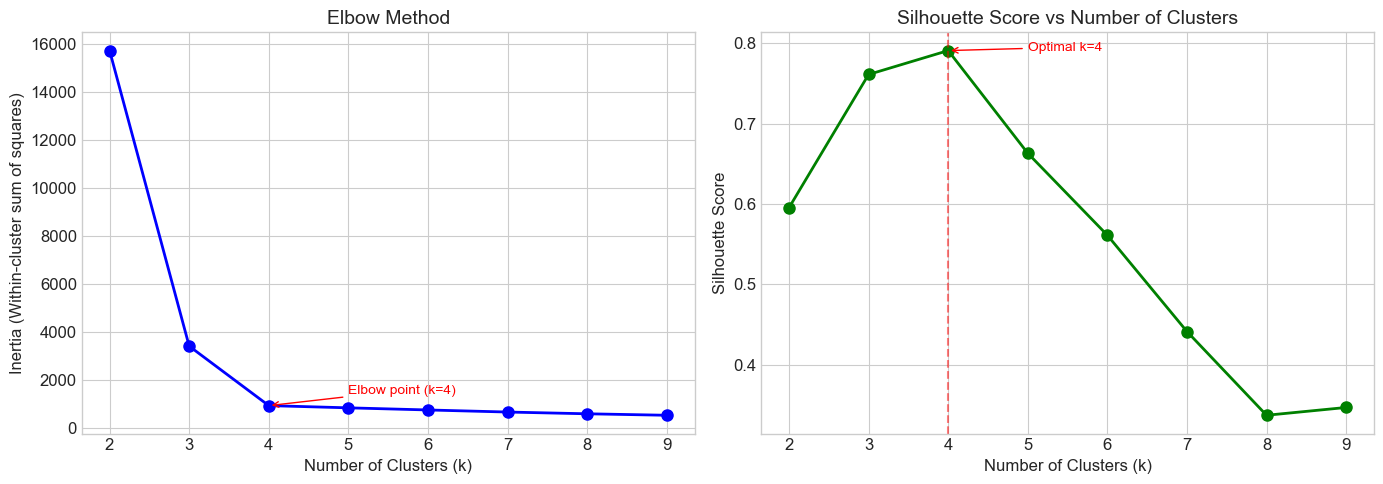

In [16]:
# Elbow Method for optimal k
k_range = range(2, 10)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
axes[0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[0].set_ylabel('Inertia (Within-cluster sum of squares)', fontsize=12)
axes[0].set_title('Elbow Method', fontsize=14)

# Annotate elbow
axes[0].annotate('Elbow point (k=4)', xy=(4, inertias[2]), xytext=(5, inertias[2] + 500),
                 arrowprops=dict(arrowstyle='->', color='red'), fontsize=10, color='red')

# Silhouette scores
axes[1].plot(k_range, silhouettes, 'go-', linewidth=2, markersize=8)
axes[1].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[1].set_ylabel('Silhouette Score', fontsize=12)
axes[1].set_title('Silhouette Score vs Number of Clusters', fontsize=14)

# Mark optimal
best_k = k_range[np.argmax(silhouettes)]
axes[1].axvline(x=best_k, color='red', linestyle='--', alpha=0.5)
axes[1].annotate(f'Optimal k={best_k}', xy=(best_k, max(silhouettes)), 
                 xytext=(best_k + 1, max(silhouettes)),
                 arrowprops=dict(arrowstyle='->', color='red'), fontsize=10, color='red')

plt.tight_layout()
plt.show()

---

## 5. Deep Learning Metrics

### 5.1 Training Curves: Loss and Accuracy

Deep learning models are evaluated by monitoring training and validation curves:

| Pattern | Diagnosis | Solution |
|---------|-----------|----------|
| Training & validation both high | Underfitting | Increase model complexity, train longer |
| Training low, validation high | Overfitting | Add regularization, dropout, early stopping |
| Both decreasing, gap small | Good fit | Continue or apply early stopping |
| Validation fluctuating | High variance | Reduce learning rate, increase batch size |

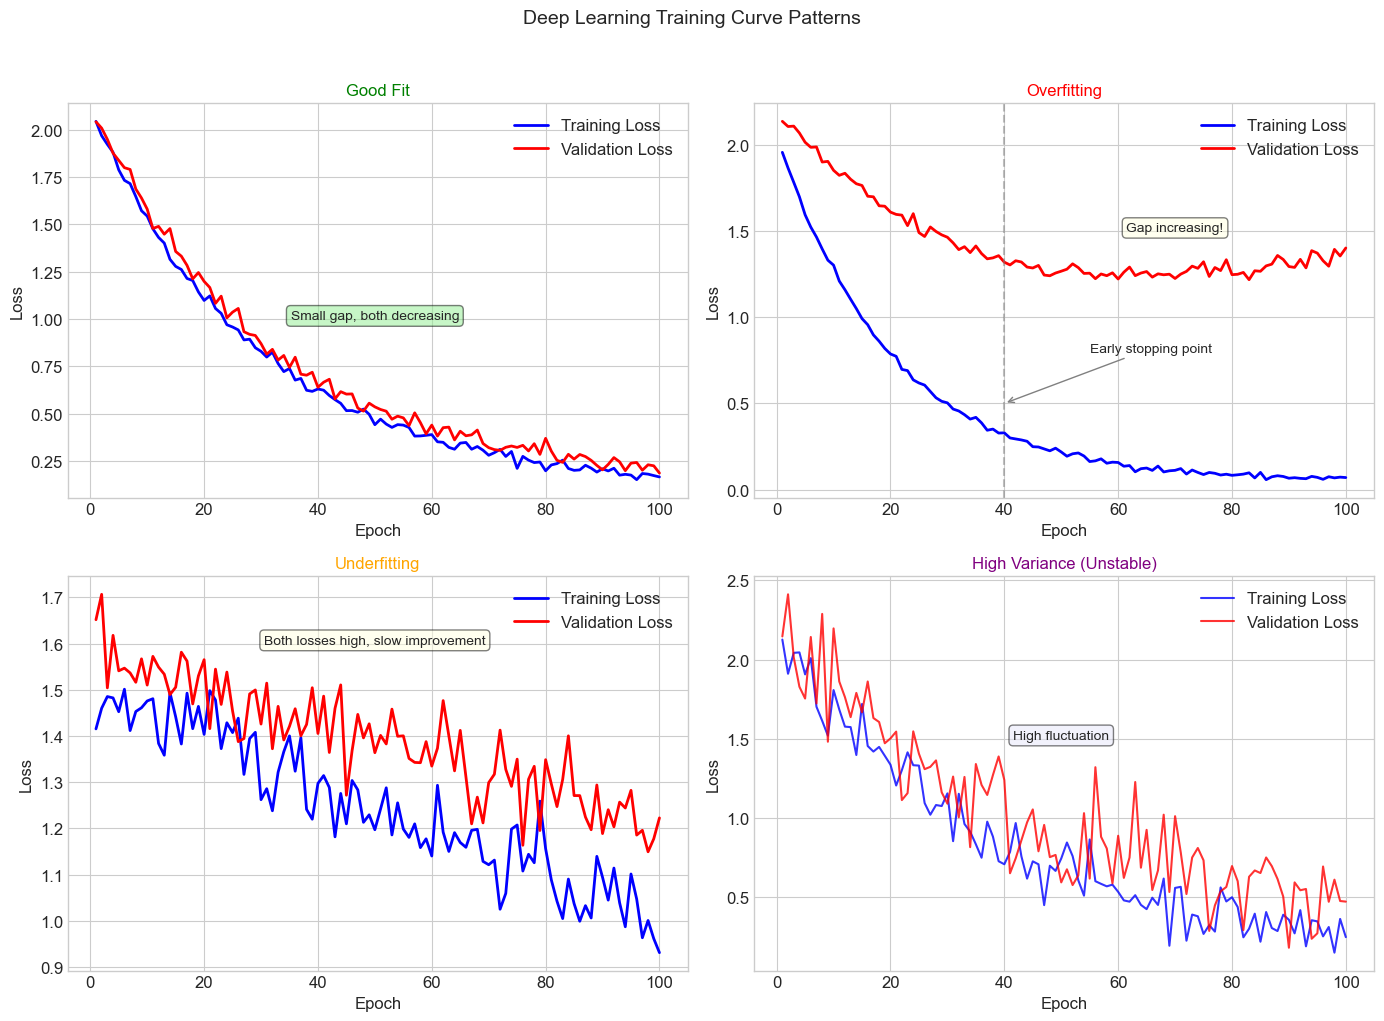

In [17]:
# Simulate training curves for different scenarios
np.random.seed(42)
epochs = np.arange(1, 101)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Good Fit
train_loss_good = 2 * np.exp(-epochs / 30) + 0.1 + np.random.normal(0, 0.02, 100)
val_loss_good = 2 * np.exp(-epochs / 30) + 0.15 + np.random.normal(0, 0.03, 100)

axes[0, 0].plot(epochs, train_loss_good, 'b-', label='Training Loss', linewidth=2)
axes[0, 0].plot(epochs, val_loss_good, 'r-', label='Validation Loss', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Good Fit', fontsize=12, color='green')
axes[0, 0].legend()
axes[0, 0].text(50, 1.0, 'Small gap, both decreasing', ha='center', fontsize=10,
                bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

# 2. Overfitting
train_loss_over = 2 * np.exp(-epochs / 20) + 0.05 + np.random.normal(0, 0.01, 100)
val_loss_over = 2 * np.exp(-epochs / 40) + 0.2 + 0.01 * epochs + np.random.normal(0, 0.03, 100)
val_loss_over = np.clip(val_loss_over, 0.3, None)

axes[0, 1].plot(epochs, train_loss_over, 'b-', label='Training Loss', linewidth=2)
axes[0, 1].plot(epochs, val_loss_over, 'r-', label='Validation Loss', linewidth=2)
axes[0, 1].axvline(x=40, color='gray', linestyle='--', alpha=0.5)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].set_title('Overfitting', fontsize=12, color='red')
axes[0, 1].legend()
axes[0, 1].annotate('Early stopping point', xy=(40, 0.5), xytext=(55, 0.8),
                    arrowprops=dict(arrowstyle='->', color='gray'), fontsize=10)
axes[0, 1].text(70, 1.5, 'Gap increasing!', ha='center', fontsize=10,
                bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

# 3. Underfitting
train_loss_under = 1.5 - 0.005 * epochs + np.random.normal(0, 0.05, 100)
val_loss_under = 1.6 - 0.004 * epochs + np.random.normal(0, 0.06, 100)

axes[1, 0].plot(epochs, train_loss_under, 'b-', label='Training Loss', linewidth=2)
axes[1, 0].plot(epochs, val_loss_under, 'r-', label='Validation Loss', linewidth=2)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].set_title('Underfitting', fontsize=12, color='orange')
axes[1, 0].legend()
axes[1, 0].text(50, 1.6, 'Both losses high, slow improvement', ha='center', fontsize=10,
                bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))

# 4. High Variance (Unstable training)
train_loss_var = 2 * np.exp(-epochs / 40) + 0.1 + np.random.normal(0, 0.1, 100)
val_loss_var = 2 * np.exp(-epochs / 40) + 0.3 + np.random.normal(0, 0.2, 100)

axes[1, 1].plot(epochs, train_loss_var, 'b-', label='Training Loss', linewidth=1.5, alpha=0.8)
axes[1, 1].plot(epochs, val_loss_var, 'r-', label='Validation Loss', linewidth=1.5, alpha=0.8)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Loss')
axes[1, 1].set_title('High Variance (Unstable)', fontsize=12, color='purple')
axes[1, 1].legend()
axes[1, 1].text(50, 1.5, 'High fluctuation', ha='center', fontsize=10,
                bbox=dict(boxstyle='round', facecolor='lavender', alpha=0.5))

plt.suptitle('Deep Learning Training Curve Patterns', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---

## 6. Metric Selection Framework

### 6.1 Decision Guide

```
What type of problem?
    |
    +-- CLASSIFICATION
    |       |
    |       +-- Balanced data? --> Accuracy, F1-Score
    |       |
    |       +-- Imbalanced data?
    |               |
    |               +-- FN costly (miss detection) --> Recall, PR-AUC
    |               |
    |               +-- FP costly (false alarm) --> Precision
    |               |
    |               +-- Both matter --> F1-Score, ROC-AUC
    |
    +-- REGRESSION
    |       |
    |       +-- Outliers present? --> MAE (robust)
    |       |
    |       +-- Large errors more costly? --> RMSE, MSE
    |       |
    |       +-- Compare models? --> R-squared, Adjusted R-squared
    |
    +-- CLUSTERING
            |
            +-- No ground truth --> Silhouette Score, Davies-Bouldin
            |
            +-- Have ground truth --> Adjusted Rand Index, NMI
```

In [18]:
# Summary table
summary_data = {
    'Problem Type': ['Binary Classification', 'Binary Classification', 
                     'Multi-class', 'Multi-class',
                     'Regression', 'Regression',
                     'Clustering', 'Clustering'],
    'Data Condition': ['Balanced', 'Imbalanced',
                       'Balanced', 'Imbalanced',
                       'No outliers', 'Has outliers',
                       'No ground truth', 'No ground truth'],
    'Recommended Metrics': ['Accuracy, F1-Score', 'Precision, Recall, PR-AUC, ROC-AUC',
                            'Accuracy, Macro-F1', 'Weighted-F1, ROC-AUC (OvR)',
                            'RMSE, R-squared', 'MAE, R-squared',
                            'Silhouette Score', 'Davies-Bouldin, Calinski-Harabasz'],
    'Primary Metric': ['F1-Score', 'PR-AUC or Recall',
                       'Macro-F1', 'Weighted-F1',
                       'RMSE', 'MAE',
                       'Silhouette', 'Davies-Bouldin']
}

summary_df = pd.DataFrame(summary_data)

print("=" * 80)
print("METRIC SELECTION QUICK REFERENCE")
print("=" * 80)
print(summary_df.to_string(index=False))

METRIC SELECTION QUICK REFERENCE
         Problem Type  Data Condition                Recommended Metrics   Primary Metric
Binary Classification        Balanced                 Accuracy, F1-Score         F1-Score
Binary Classification      Imbalanced Precision, Recall, PR-AUC, ROC-AUC PR-AUC or Recall
          Multi-class        Balanced                 Accuracy, Macro-F1         Macro-F1
          Multi-class      Imbalanced         Weighted-F1, ROC-AUC (OvR)      Weighted-F1
           Regression     No outliers                    RMSE, R-squared             RMSE
           Regression    Has outliers                     MAE, R-squared              MAE
           Clustering No ground truth                   Silhouette Score       Silhouette
           Clustering No ground truth  Davies-Bouldin, Calinski-Harabasz   Davies-Bouldin


---

## 7. Exercises

### Exercise 1: Interpret a Confusion Matrix

A medical diagnostic model produces the following confusion matrix for disease detection:

```
                Predicted Healthy  Predicted Sick
Actually Healthy       850              50
Actually Sick           30             70
```

Calculate and interpret:
1. Accuracy
2. Precision
3. Recall (Sensitivity)
4. Specificity
5. Which metric is most important for this use case? Why?

In [19]:
# Exercise 1: Your solution here
# Given values
TN = 850  # Actually Healthy, Predicted Healthy
FP = 50   # Actually Healthy, Predicted Sick
FN = 30   # Actually Sick, Predicted Healthy
TP = 70   # Actually Sick, Predicted Sick

# Calculate metrics
accuracy_ex1 = None  # Your calculation here
precision_ex1 = None  # Your calculation here
recall_ex1 = None  # Your calculation here
specificity_ex1 = None  # Your calculation here

# Uncomment and complete:
# print(f"Accuracy: {accuracy_ex1:.4f}")
# print(f"Precision: {precision_ex1:.4f}")
# print(f"Recall: {recall_ex1:.4f}")
# print(f"Specificity: {specificity_ex1:.4f}")
# print("\nMost important metric: _____ because _____")

### Exercise 2: Choose the Right Metric

For each scenario, identify the most appropriate primary metric and explain why:

1. **Spam email detection** where users hate missing important emails
2. **Credit card fraud detection** where missing fraud is very costly
3. **Product recommendation** with 3 categories (electronics, clothing, food)
4. **House price prediction** in a market with some luxury outliers
5. **Customer segmentation** for marketing campaigns

In [20]:
# Exercise 2: Your answers here
exercise2_answers = {
    "Spam detection": "Metric: _____, Reason: _____",
    "Fraud detection": "Metric: _____, Reason: _____",
    "Product recommendation": "Metric: _____, Reason: _____",
    "House price prediction": "Metric: _____, Reason: _____",
    "Customer segmentation": "Metric: _____, Reason: _____"
}

# Uncomment to print your answers:
# for scenario, answer in exercise2_answers.items():
#     print(f"{scenario}: {answer}")

### Exercise 3: Compare ROC Curves

Two models are trained for the same binary classification task. Analyze their ROC curves and determine which is better.

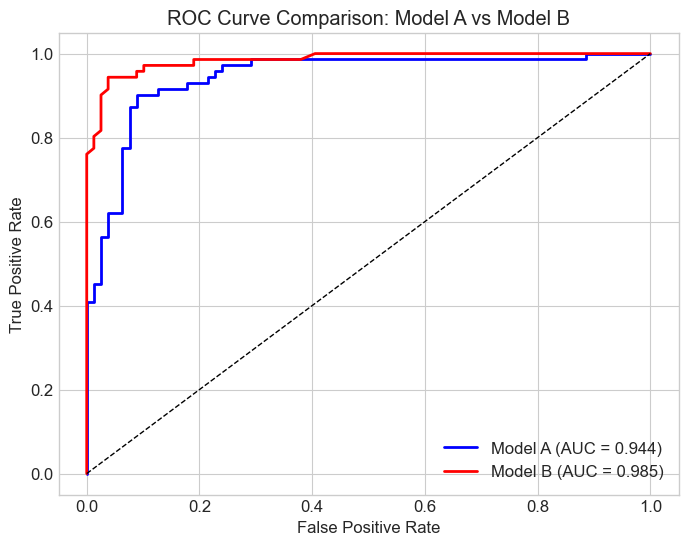


YOUR ANALYSIS:


In [21]:
# Exercise 3: Compare two models
np.random.seed(42)

# Generate sample data
X_ex3, y_ex3 = make_classification(n_samples=500, n_features=10, random_state=42)
X_train_ex3, X_test_ex3, y_train_ex3, y_test_ex3 = train_test_split(
    X_ex3, y_ex3, test_size=0.3, random_state=42
)

# Model A: Logistic Regression
model_a = LogisticRegression(random_state=42)
model_a.fit(X_train_ex3, y_train_ex3)
y_proba_a = model_a.predict_proba(X_test_ex3)[:, 1]

# Model B: Random Forest
model_b = RandomForestClassifier(n_estimators=100, random_state=42)
model_b.fit(X_train_ex3, y_train_ex3)
y_proba_b = model_b.predict_proba(X_test_ex3)[:, 1]

# Plot both ROC curves
fig, ax = plt.subplots(figsize=(8, 6))

fpr_a, tpr_a, _ = roc_curve(y_test_ex3, y_proba_a)
fpr_b, tpr_b, _ = roc_curve(y_test_ex3, y_proba_b)

auc_a = roc_auc_score(y_test_ex3, y_proba_a)
auc_b = roc_auc_score(y_test_ex3, y_proba_b)

ax.plot(fpr_a, tpr_a, 'b-', linewidth=2, label=f'Model A (AUC = {auc_a:.3f})')
ax.plot(fpr_b, tpr_b, 'r-', linewidth=2, label=f'Model B (AUC = {auc_b:.3f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1)

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve Comparison: Model A vs Model B')
ax.legend()
plt.show()

# Your analysis:
print("\n" + "="*50)
print("YOUR ANALYSIS:")
print("="*50)
# Write your comparison and conclusion here:
# print("Which model is better? _____")
# print("By how much? _____")
# print("At what FPR threshold does Model B become better? _____")

### Exercise 4: Diagnose Residual Plots

Examine the residual plot below and identify:
1. What pattern do you see?
2. What problem does this indicate?
3. What would you do to fix it?

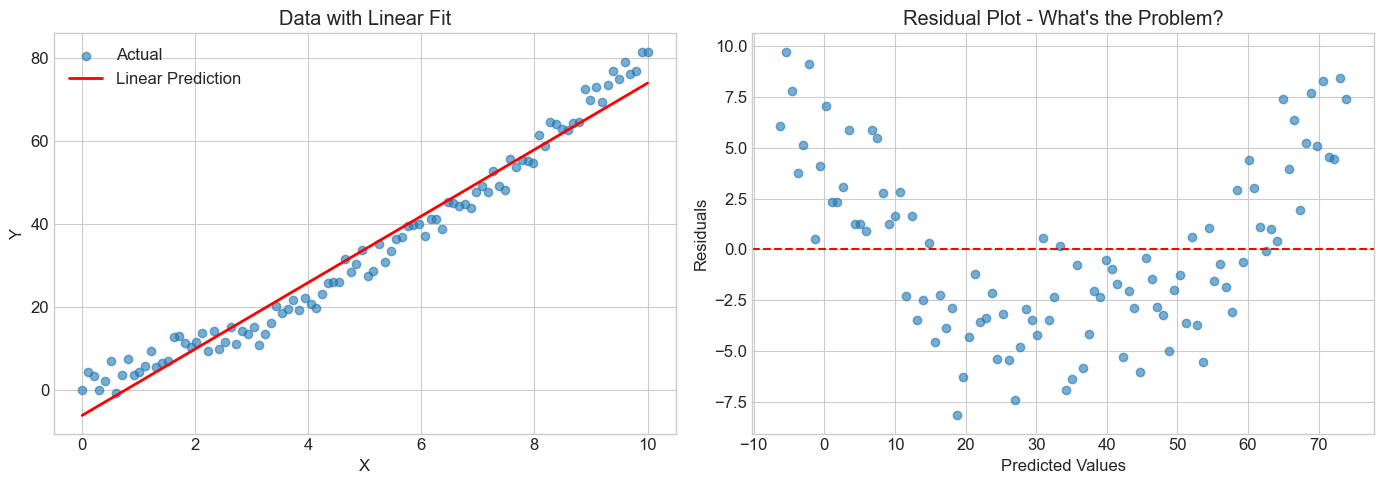


YOUR DIAGNOSIS:


In [22]:
# Exercise 4: Diagnose residuals
np.random.seed(123)

# Generate data with non-linear relationship
X_ex4 = np.linspace(0, 10, 100).reshape(-1, 1)
y_true_ex4 = 2 + 3*X_ex4.ravel() + 0.5*X_ex4.ravel()**2 + np.random.normal(0, 2, 100)

# Fit a LINEAR model (intentionally wrong)
from sklearn.linear_model import LinearRegression
lin_model = LinearRegression()
lin_model.fit(X_ex4, y_true_ex4)
y_pred_ex4 = lin_model.predict(X_ex4)

# Residuals
residuals_ex4 = y_true_ex4 - y_pred_ex4

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(X_ex4, y_true_ex4, alpha=0.6, label='Actual')
axes[0].plot(X_ex4, y_pred_ex4, 'r-', linewidth=2, label='Linear Prediction')
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')
axes[0].set_title('Data with Linear Fit')
axes[0].legend()

# Residual plot
axes[1].scatter(y_pred_ex4, residuals_ex4, alpha=0.6)
axes[1].axhline(y=0, color='r', linestyle='--')
axes[1].set_xlabel('Predicted Values')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot - What\'s the Problem?')

plt.tight_layout()
plt.show()

print("\n" + "="*50)
print("YOUR DIAGNOSIS:")
print("="*50)
# print("1. Pattern observed: _____")
# print("2. Problem: _____")
# print("3. Solution: _____")

### Exercise 5: Evaluate Clustering

Run K-Means with different values of k and determine the optimal number of clusters using multiple metrics.

 k      Inertia  Silhouette  Davies-Bouldin
 2 11308.983040    0.603436        0.474993
 3  2671.118226    0.724451        0.434655
 4   982.539712    0.765766        0.300029
 5   488.666022    0.734717        0.367939
 6   450.013715    0.661530        0.615316
 7   414.318117    0.546820        0.824783
 8   379.729729    0.458213        0.952499
 9   347.319825    0.362102        1.121558
10   312.609244    0.323824        1.147141


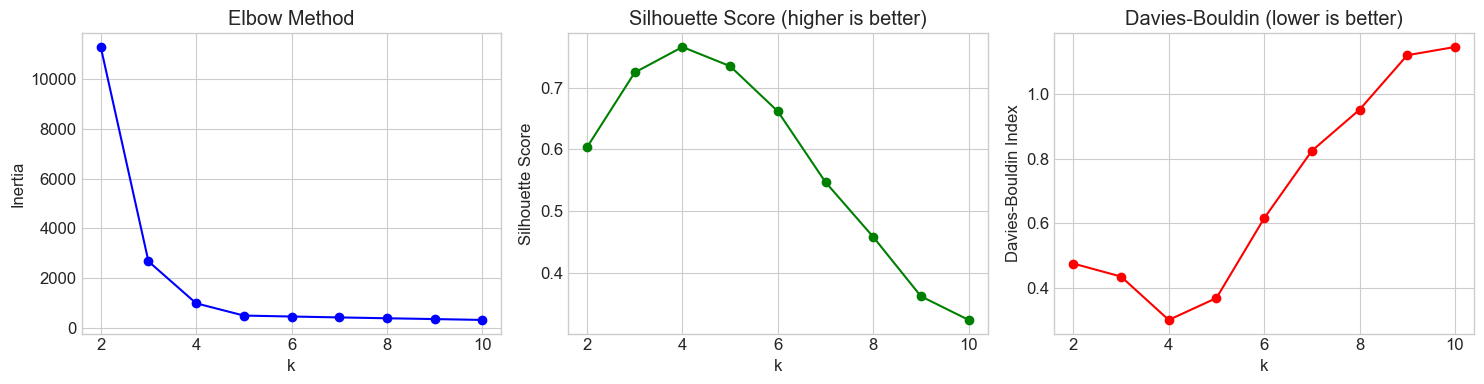


YOUR ANALYSIS:


In [23]:
# Exercise 5: Find optimal k
np.random.seed(42)

# Generate clustering data (unknown number of true clusters to you)
X_ex5, _ = make_blobs(n_samples=400, centers=5, cluster_std=0.8, random_state=42)

# Your task: Try k = 2 to 10 and find the optimal k
k_values = range(2, 11)

# Store results
results_ex5 = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_ex5)
    
    results_ex5.append({
        'k': k,
        'Inertia': km.inertia_,
        'Silhouette': silhouette_score(X_ex5, labels),
        'Davies-Bouldin': davies_bouldin_score(X_ex5, labels)
    })

results_ex5_df = pd.DataFrame(results_ex5)
print(results_ex5_df.to_string(index=False))

# Plot the metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(k_values, results_ex5_df['Inertia'], 'bo-')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')

axes[1].plot(k_values, results_ex5_df['Silhouette'], 'go-')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score (higher is better)')

axes[2].plot(k_values, results_ex5_df['Davies-Bouldin'], 'ro-')
axes[2].set_xlabel('k')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].set_title('Davies-Bouldin (lower is better)')

plt.tight_layout()
plt.show()

print("\n" + "="*50)
print("YOUR ANALYSIS:")
print("="*50)
# print(f"Optimal k based on Elbow: _____")
# print(f"Optimal k based on Silhouette: _____")
# print(f"Optimal k based on Davies-Bouldin: _____")
# print(f"Final recommendation: k = _____")

---

## Summary

### Key Takeaways

1. **Never rely on accuracy alone** - especially for imbalanced data
2. **Choose metrics based on business context** - what errors are more costly?
3. **Use multiple metrics** - they reveal different aspects of model performance
4. **Visualize your metrics** - ROC curves, residual plots, and silhouette plots tell stories
5. **Consider the threshold** - default 0.5 may not be optimal for your use case

### Quick Reference Card

| If you care about... | Use this metric |
|---------------------|------------------|
| Not missing positive cases | Recall |
| Not having false alarms | Precision |
| Balance of both | F1-Score |
| Overall discrimination | ROC-AUC |
| Imbalanced data | PR-AUC |
| Typical prediction error | RMSE |
| Robust to outliers | MAE |
| Variance explained | R-squared |
| Cluster quality | Silhouette Score |

---

**Next Steps:** Apply these metrics to your CART models (Module 04) and Deep Learning models (Module 05)!

---

## How this is used in real work

Every model review, every stakeholder conversation and every production alert threshold is this chapter. The metric you pick decides what the model optimises for, which decides who it fails. That is a design decision, not a reporting one.

## Where this goes next

Module 02 (CART), 03 (Unsupervised) and 05 (Deep Learning) all assume these metrics.